# Lab 7.2 — Can fixed-loop SampleNTT still leak through power?

**ChipWhisperer Husky + CW308_STM32F4 · ProjectTempo top-level A1 (FLS)**

This lab asks whether **one physical power trace predicts the first candidate's accept/reject decision on a new seed** after replacing A0 with the Fixed Loop Sampler. A1 processes 280 pairs on every call and uses masks and fixed memory scans. Its values can still affect power consumption. We measure the outcome; success is not assumed.

Use **chipwhisperer-new/.venv** as the notebook kernel. Disconnect the A0 notebook first, then use a fresh kernel and run these nine sections in order. The hardware cells build and program the **STM32 target**, not the Husky USB firmware or FPGA. Installing or opening this notebook does not run a capture.

The [short A0 lab](Lab%207_1%20-%20ML-KEM%20SampleNTT%20Power%20Lab.ipynb) and [full A0 method](Full%20SampleNTT%20Method.ipynb) live beside this notebook. [Tempo paper](https://eprint.iacr.org/2025/1399) · [Authors' implementation](https://github.com/afonsoarriaga/ProjectTempo).

We use the pinned **top-level `src/algorithm_a1.c`**, which differs from the authors' pqm4 copy. Fixed loops are a source-level design: this notebook does not certify constant-time machine code. Separate duration measurements help distinguish timing evidence from power classification.


## 1. Load and configure

Default: 128 seeds per class for training and another 128 per class for testing, **512 captures total, one per seed**. Calibration/check captures are separate. The classes are balanced; candidate one is accepted, and the output first fills on candidate 320. FLS still visits all 560 candidates, including the suffix after filling. This conditions the input population rather than estimating accuracy on arbitrary seeds.

The low-gain advisory is suppressed by default, following the working A0 setup. **Clipping detection remains enabled.** Pick gain before training. To resume, set `RESUME_RUN` to the printed run folder and keep all settings identical. Each notebook needs its own kernel.


In [1]:
from pathlib import Path
import sys, importlib

PER_CLASS = 128
GAIN_DB = 10.0
SCOPE_SN = None                 # Set a serial only if multiple Huskys are attached.
SUPPRESS_LOW_GAIN_WARNING = True
RESUME_RUN = None               # Paste a previous fls-... results directory to resume.

here = Path.cwd().resolve()
roots = [here, *list(here.parents)[:6]]
tails = ('mlkem-samplentt-power-lab', 'custom/mlkem-samplentt-power-lab',
         'courses/custom/mlkem-samplentt-power-lab',
         'jupyter/courses/custom/mlkem-samplentt-power-lab')
candidates = [p / tail for p in roots for tail in tails]
if (here / 'analysis/fls.py').is_file():
    candidates.insert(0, here)
LAB = next((p for p in candidates if (p / 'analysis/fls.py').is_file()), None)
if LAB is None:
    raise FileNotFoundError('Open this notebook from chipwhisperer-new or its jupyter/courses/custom folder.')
REPO = next(p for p in LAB.parents if (p / 'firmware/mcu/Makefile.inc').is_file())
if globals().get('fls') is not None and fls.scope is not None:
    raise RuntimeError('Disconnect the existing FLS session before rerunning setup.')
sys.path.insert(0, str(LAB))
for name in ('analysis.distinguisher', 'analysis.proof', 'analysis.fls',
             'capture.hardware', 'capture.cohort', 'firmware.build', 'capture.lab', 'capture.fls'):
    module = importlib.import_module(name)
    if not Path(module.__file__).resolve().is_relative_to(LAB.resolve()):
        raise RuntimeError(f'{name} is cached from another checkout. Restart the kernel.')
    importlib.reload(module)
from capture.fls import FLSPowerLab
fls = FLSPowerLab(REPO, per_class=PER_CLASS, gain_db=GAIN_DB, serial=SCOPE_SN,
                  resume=RESUME_RUN, suppress_low_gain_warning=SUPPRESS_LOW_GAIN_WARNING)
print('Python:', sys.executable)
print('ChipWhisperer:', fls.cw.__version__, fls.cw.__file__)


FLS results: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/fls-20261029T010815Z-1da2fa
Python: /home/ubuntu/Desktop/work/chipwhisperer-new/.venv/bin/python
ChipWhisperer: 7.0.0 /home/ubuntu/Desktop/work/chipwhisperer-new/software/chipwhisperer/__init__.py


## 2. Build FLS and its separate calibration image

This cell compiles both images, checks the pinned sampler source hashes, and saves build logs and assembly. It does not open USB. The measurement image contains the ordinary sampler; only the calibration image records the first two SHAKE-call boundaries.

The printed `.asm` file is available for checking `algorithmA1` and its helpers. Loop branches should depend on fixed bounds, not candidate validity. Compiler output and memory accesses matter: stable timings alone do not prove this property. Build metadata deliberately retains `constant_time_verified = False`.


In [2]:
fls.build()


Pinned top-level algorithmA1; sampler sources are hash checked.
Measurement image SHA256: b1913a9f200fec71840e19211f65144e45fffdc9997e614549481c29d8020478
Assembly to inspect: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/firmware/fls/samplentt-fls-CW308_STM32F4.asm
Fixed loops in source are not a certificate of constant-time machine code.


'b1913a9f200fec71840e19211f65144e45fffdc9997e614549481c29d8020478'

## 3. Locate the first FLS pair

This connects Husky, programs the **calibration target image**, warms the target, and measures eight balanced calibration inputs. Between the first SHAKE return and the second SHAKE entry, A1 performs both 256-element scans for the first pair. The printed cycle counts compare rejected and accepted first candidates.

The ADC stores only a short window during calibration; the DWT markers and trigger counter measure later events through completion. A padded window is derived from the markers and saved once. Wrapping and code layout change timing, so these are approximate guides. **Calibration traces never enter training or testing.** A resumed run reuses its original window.


In [3]:
if fls.scope is None:
    fls.connect()
localization = fls.localize()


Connected Husky: 502032204c5846303230373132313032
Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 15579 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 15579 bytes


FLS first-pair calibration:   0%|          | 0/8 [00:00<?, ?it/s]

Calibration first-pair CPU cycles (reject / accept): {'0': [7236, 7236, 7236, 7236], '1': [7236, 7236, 7236, 7236]}
Measurement window: offset 93168 ; samples 37248


## 4. Restore ordinary FLS and inspect the waveform

This programs the uninstrumented measurement image, verifies its FLS identity and polynomial digests, and shows a separate check trace. Orange markers are approximate first-pair boundaries from calibration. Check that the waveform has useful variation and no clipping. If gain needs changing, start a fresh run before training.

The captured window is deliberately shorter than the full FLS operation. The **whole-operation trigger duration** is still recorded for every input; it is read after computation completes. The first two measurement calls warm the target and are excluded from model data.


Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 15283 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 15283 bytes
Representative FLS identity and polynomial digests verified.
Check ADC range: 1654 to 2459 ; complete-operation time: 295.059 ms
Only the first-pair window is recorded. Trigger duration still covers the entire operation.
Clipping checks enabled. Low-gain advisory suppressed: True


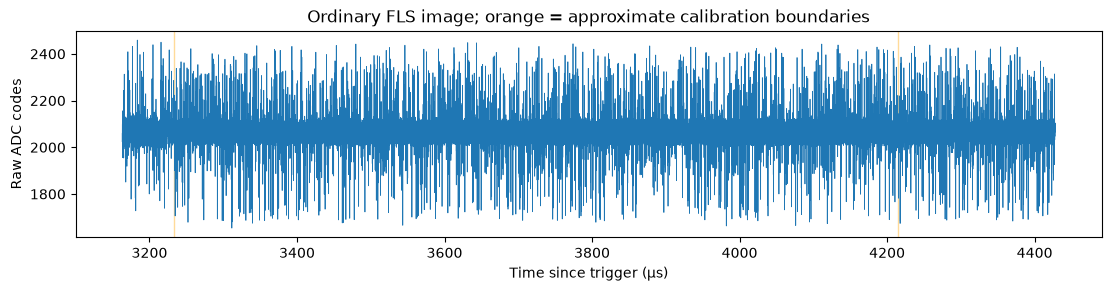

In [4]:
fls.restore_measurement()


## 5. Capture training data

The lab declares disjoint, balanced training/test seeds and excludes prior planned seeds and recorded check inputs. Labels are independently calculated from SHAKE, and every target output is checked by its full polynomial digest. Trial order is randomized. Each success is checkpointed; a failed attempt is logged and stops acquisition. Rerunning resumes the remaining trials without discarding difficult seeds.


In [5]:
fls.collect_training()


FLS training captures:   0%|          | 0/256 [00:00<?, ?it/s]

256 verified FLS training captures; one per seed.


256

## 6. Select and freeze using training only

Four-fold cross-validation searches windows inside the calibrated first-pair capture. Sample-point selection runs inside each fold. A regularized logistic classifier is then fitted to training data; a separate linear model uses total duration. The best searched CV score is an optimistic development diagnostic, **not the final result**.

This saves numeric model coefficients, selected points, a fixed threshold, source hashes, image/settings identity, and the training-data fingerprint. It cannot overwrite an existing frozen model. There is no single shuffled-training-label model presented as a passed negative control.


In [6]:
fls.freeze()


Frozen FLS model: 24c0d7e8a4e09b4e06045f6d9f0597230f07e1f4d17078ab7cf67a294efa9da3
Relative power window: [26624, 34816]
Best development CV BA: 1.0
That searched CV maximum is optimistic. Only the fresh test estimates performance.


'24c0d7e8a4e09b4e06045f6d9f0597230f07e1f4d17078ab7cf67a294efa9da3'

## 7. Capture the fresh test

All test seeds are new. Each capture is stamped with the already frozen model hash. Keep gain, clock, window, warning policy, and firmware fixed. Once these results have been seen, any model or window change requires a new plan and a fresh test.


In [7]:
fls.collect_test()


FLS fresh-test captures:   0%|          | 0/256 [00:00<?, ?it/s]

256 verified fresh FLS test captures; no refitting.


256

## 8. Evaluate power and timing separately

The table reports correct predictions, balanced accuracy (chance = 50%), conservative exact 95% bounds, and AUC (chance = 0.5). Exact bounds retain uncertainty even for a perfect finite test. The fixed-model test-label permutation p-value measures prediction/label association. All planned captures must be present.

The timing diagnostics compare whole-operation durations with a Welch mean test and a KS distribution test, using a 0.025 threshold per test. Quantized, constant counters are handled explicitly. No detected timing difference **does not prove constant time**, and whole-operation timing can hide local variation. Calibration first-pair timing and compiled-code inspection provide additional context.

- Power succeeds: evidence of first-candidate information in this FLS build's traces. Establishing the physical mechanism requires further work.
- Timing also differs: investigate it before describing the result as independent of timing leakage.
- Power is near chance: this particular experiment did not demonstrate a distinguisher. Preserve the negative result; it does not prove resistance to every power attack.

The figures show power scores, whole-operation durations, and the confusion matrix. `report.json` retains capture failures/retries. These results concern known public seeds on a warmed target; they do not demonstrate secret-key recovery.

To review a completed run without hardware after restarting: run section 1 with its `RESUME_RUN`, then this section.


| Frozen model | Correct | Balanced accuracy (95% bounds) | AUC |
|---|---:|---:|---:|
| Power | 250/256 | 97.66% (92.62–99.59%) | 0.991 |
| Total timing | 128/256 | 50.00% (48.32–51.68%) | 0.500 |

Fresh-test power discrimination is supported for this FLS build.
Power exact fixed-model label-permutation p: 1.55e-65
Mean accept-minus-reject duration: 0.0 CPU cycles
Timing Welch p: 1 ; KS p: 1
No duration association detected by these tests. This does not prove constant time.


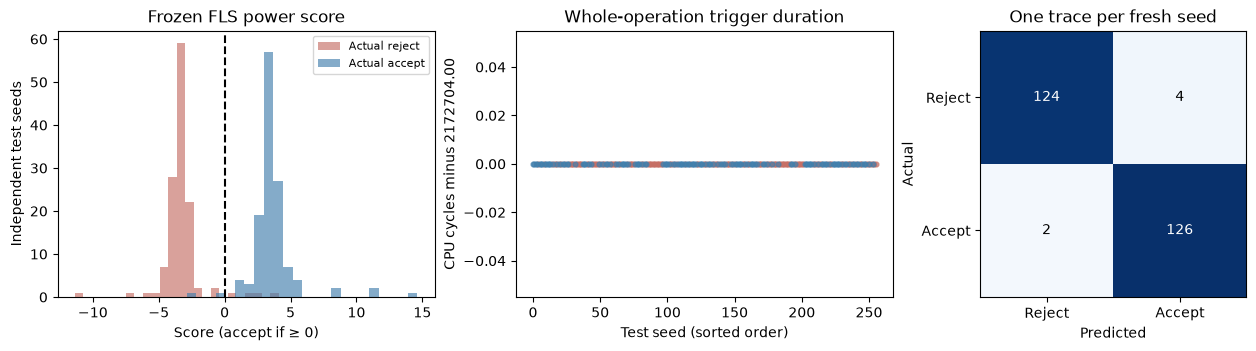

Saved: /home/ubuntu/Desktop/work/chipwhisperer-new/jupyter/courses/custom/mlkem-samplentt-power-lab/results/runs/fls-20261029T010815Z-1da2fa/report.json


In [8]:
report = fls.results()


## 9. Disconnect

Release the device before opening another hardware notebook. If you interrupt a capture, run this cell before restarting the kernel.


In [ ]:
fls.close()
print('Disconnected.')
